In [1]:
!pip install -q segmentation-models-pytorch rasterio

from google.colab import drive
drive.mount('/content/drive')

import os, sys
REPO = '/content/sar-flood-unet'
if os.path.exists(REPO):
    !git -C {REPO} pull -q
else:
    !git clone -q https://github.com/Ronnelpabalan/sar-flood-unet.git {REPO}
sys.path.insert(0, REPO)

import numpy as np
import pandas as pd
import torch
import segmentation_models_pytorch as smp
from src.dataset import Sen1Floods11, load_chip
from src.metrics import MetricAccumulator

DATA_DIR = '/content/drive/MyDrive/sen1floods11'
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

Mounted at /content/drive
device: cuda


In [2]:
ckpt = torch.load(f'{DATA_DIR}/checkpoints/unet_resnet34_best.pth', map_location=device)
model = smp.Unet(encoder_name='resnet34', encoder_weights=None,
                 in_channels=2, classes=1).to(device)
model.load_state_dict(ckpt['model_state'])
model.eval()
print(f"Loaded epoch {ckpt['epoch']} | val IoU at save time {ckpt['val_iou']:.3f}")

Loaded epoch 32 | val IoU at save time 0.681


In [3]:
eval_sets = {s: Sen1Floods11(DATA_DIR, s, augment=False) for s in ['valid', 'test', 'bolivia']}

@torch.no_grad()
def predict(ds, batch_size=8):
    """Return a (N, H, W) bool array: True where the U-Net predicts water (probability > 0.5)."""
    out = []
    for i in range(0, len(ds), batch_size):
        x = torch.stack([ds[j][0] for j in range(i, min(i + batch_size, len(ds)))]).to(device)
        out.append((model(x) > 0).squeeze(1).cpu().numpy())
    return np.concatenate(out)

preds, rows = {}, []
for split, ds in eval_sets.items():
    preds[split] = predict(ds)
    acc = MetricAccumulator()
    for p, l in zip(preds[split], ds.labels):
        acc.add(p, l)
    rows.append({'method': 'U-Net (ResNet34)', 'split': split, **acc.compute()})
    print(f"{split:8s} scored pixels: {sum(acc.counts.values()):,}")

unet_results = pd.DataFrame(rows).round(3)
unet_results

valid    scored pixels: 20,274,154
test     scored pixels: 20,443,959
bolivia  scored pixels: 2,824,434


,method,split,iou,f1,precision,recall,accuracy
0,U-Net (ResNet34),valid,0.681,0.810,0.832,0.789,0.959
1,U-Net (ResNet34),test,0.675,0.806,0.819,0.793,0.953
2,U-Net (ResNet34),bolivia,0.576,0.731,0.799,0.674,0.921


In [4]:
baseline = pd.read_csv(f'{REPO}/results/baseline_metrics.csv')
allres = pd.concat([baseline, unet_results], ignore_index=True)

cols = ['iou', 'f1', 'precision', 'recall', 'accuracy']
for split in ['test', 'bolivia']:
    print(f'\n=== {split.upper()} ===')
    display(allres[allres['split'] == split].set_index('method')[cols])

unet_results.to_csv('/content/unet_metrics.csv', index=False)
from google.colab import files
files.download('/content/unet_metrics.csv')


=== TEST ===


,iou,f1,precision,recall,accuracy
method,,,,,
Otsu VV (per chip),0.211,0.349,0.230,0.727,0.666
Fixed VV < -16.8 dB,0.464,0.634,0.774,0.536,0.924
Fixed VH < -23.6 dB,0.533,0.695,0.747,0.650,0.930
U-Net (ResNet34),0.675,0.806,0.819,0.793,0.953



=== BOLIVIA ===


,iou,f1,precision,recall,accuracy
method,,,,,
Otsu VV (per chip),0.350,0.519,0.378,0.826,0.755
Fixed VV < -16.8 dB,0.436,0.608,0.881,0.464,0.904
Fixed VH < -23.6 dB,0.535,0.697,0.870,0.581,0.919
U-Net (ResNet34),0.576,0.731,0.799,0.674,0.921


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
T_VV, T_VH = -16.8, -23.6     # train-optimised thresholds from notebooks/02_baseline.ipynb

test_ds = eval_sets['test']
acc = {}
for i, cid in enumerate(test_ds.chip_ids):
    event = cid.split('_')[0]
    s1, _ = load_chip(DATA_DIR, cid)
    lab = test_ds.labels[i]                         # already -1 where SAR is missing
    for method, p in [('U-Net', preds['test'][i]),
                      ('Fixed VH', s1[1] < T_VH),
                      ('Fixed VV', s1[0] < T_VV)]:
        acc.setdefault((event, method), MetricAccumulator()).add(p, lab)

ev = pd.DataFrame([{'event': e, 'method': m, 'iou': a.compute()['iou']} for (e, m), a in acc.items()])
ev = ev.pivot(index='event', columns='method', values='iou')[['Fixed VV', 'Fixed VH', 'U-Net']]
ev['chips'] = pd.Series([c.split('_')[0] for c in test_ds.chip_ids]).value_counts()
ev['U-Net gain vs VH'] = ev['U-Net'] - ev['Fixed VH']
ev.round(3).sort_values('U-Net gain vs VH', ascending=False)

method,Fixed VV,Fixed VH,U-Net,chips,U-Net gain vs VH
event,,,,,
Somalia,0.179,0.256,0.471,6,0.215
USA,0.327,0.379,0.582,14,0.203
Paraguay,0.494,0.466,0.659,14,0.193
Nigeria,0.696,0.713,0.889,4,0.176
Pakistan,0.117,0.150,0.311,6,0.161
Ghana,0.387,0.453,0.582,11,0.129
Mekong,0.739,0.724,0.830,6,0.106
Spain,0.621,0.640,0.732,6,0.092
Sri-Lanka,0.203,0.717,0.801,9,0.084


In [6]:
from src.metrics import confusion_counts, metrics_from_counts

chip_rows = []
for i, cid in enumerate(test_ds.chip_ids):
    lab = test_ds.labels[i]
    n_valid = int((lab != -1).sum())
    if n_valid == 0:
        continue                                    # Paraguay_34417: no SAR data
    s1, _ = load_chip(DATA_DIR, cid)
    chip_rows.append({'chip': cid, 'event': cid.split('_')[0],
                      'water_%': 100 * (lab == 1).sum() / n_valid,
                      'iou_vh': metrics_from_counts(confusion_counts(s1[1] < T_VH, lab))['iou'],
                      'iou_unet': metrics_from_counts(confusion_counts(preds['test'][i], lab))['iou']})
chips = pd.DataFrame(chip_rows)
chips['gain'] = chips['iou_unet'] - chips['iou_vh']

cand = chips[chips['water_%'] >= 2].sort_values('gain').reset_index(drop=True)
mid = len(cand) // 2
picks = pd.concat([cand.tail(2).iloc[::-1], cand.iloc[[mid - 1, mid]], cand.head(2)])
picks['why'] = ['largest U-Net gain'] * 2 + ['typical (median gain)'] * 2 + ['U-Net worst vs. threshold'] * 2
print(len(cand), 'test chips with >= 2% water')
print('U-Net better than VH on', int((cand['gain'] > 0).sum()), 'of', len(cand), 'of them')
picks.round(3)

46 test chips with >= 2% water
U-Net better than VH on 42 of 46 of them


,chip,event,water_%,iou_vh,iou_unet,gain,why
45,Somalia_94102,Somalia,5.259,0.236,0.733,0.497,largest U-Net gain
44,Pakistan_694942,Pakistan,9.653,0.265,0.721,0.456,largest U-Net gain
22,India_952728,India,3.099,0.085,0.193,0.108,typical (median gain)
23,India_399883,India,51.996,0.655,0.764,0.109,typical (median gain)
0,India_747992,India,44.765,0.289,0.153,-0.136,U-Net worst vs. threshold
1,Somalia_685158,Somalia,13.712,0.278,0.241,-0.037,U-Net worst vs. threshold


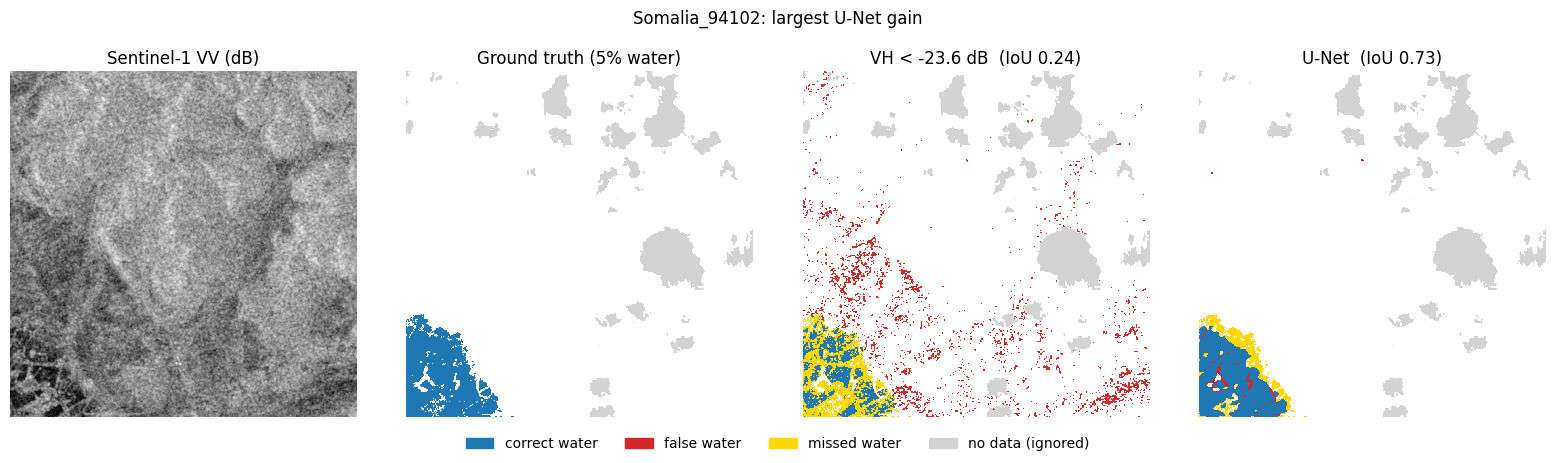

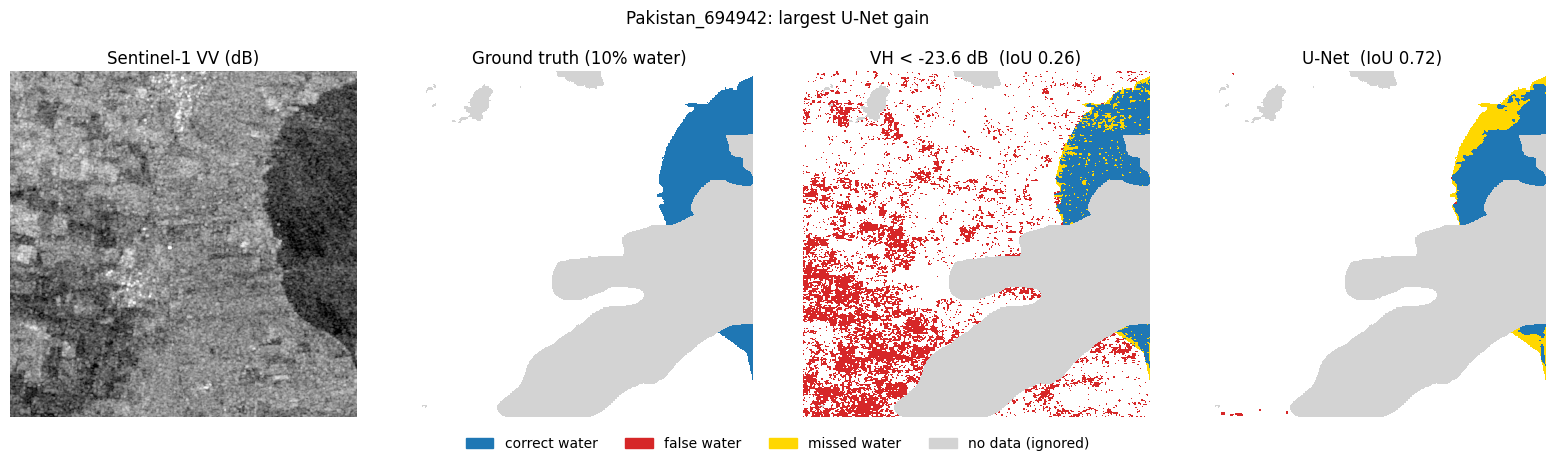

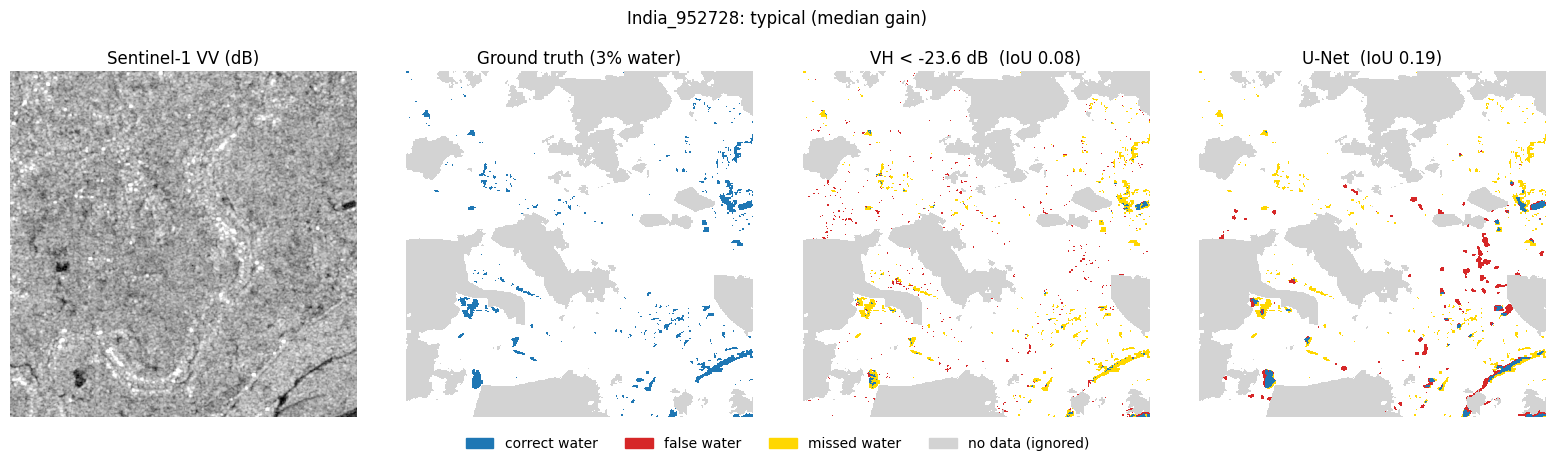

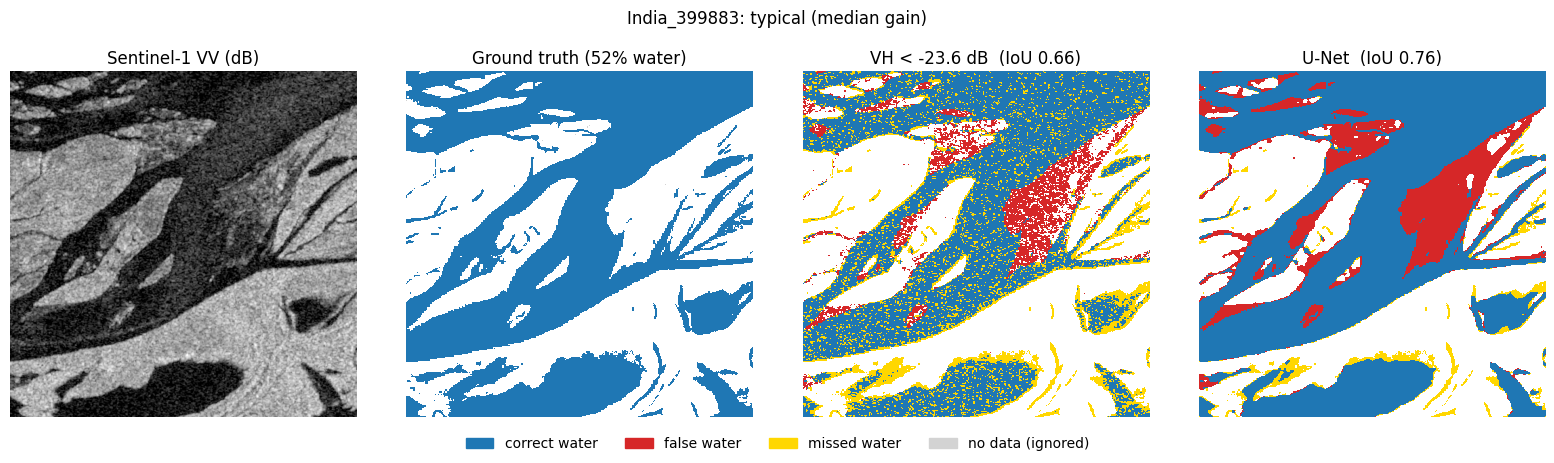

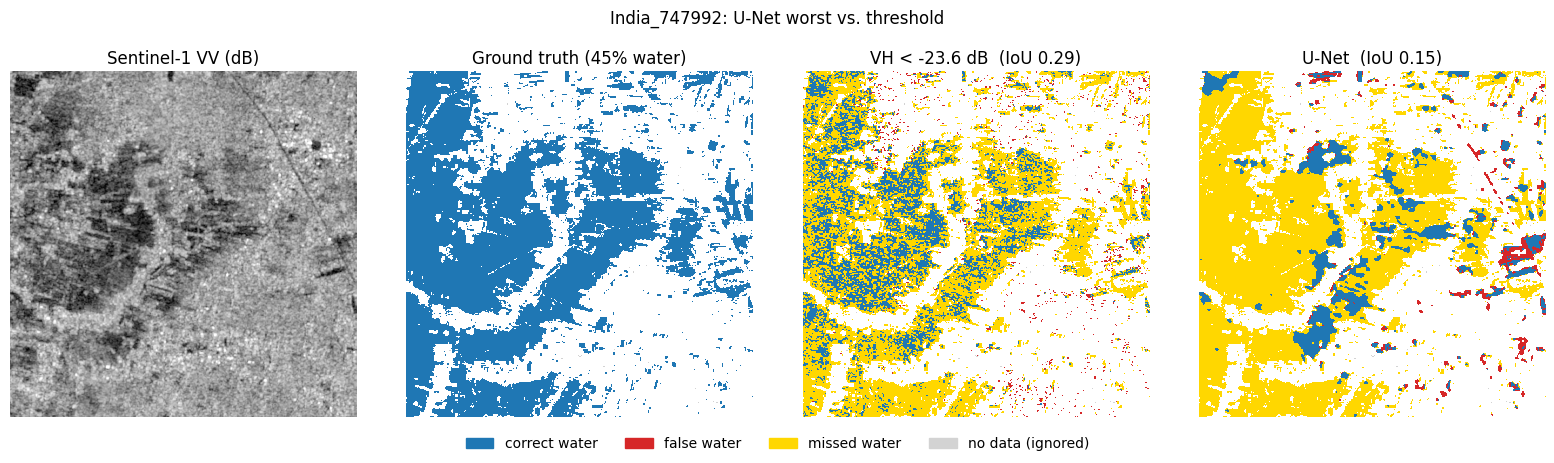

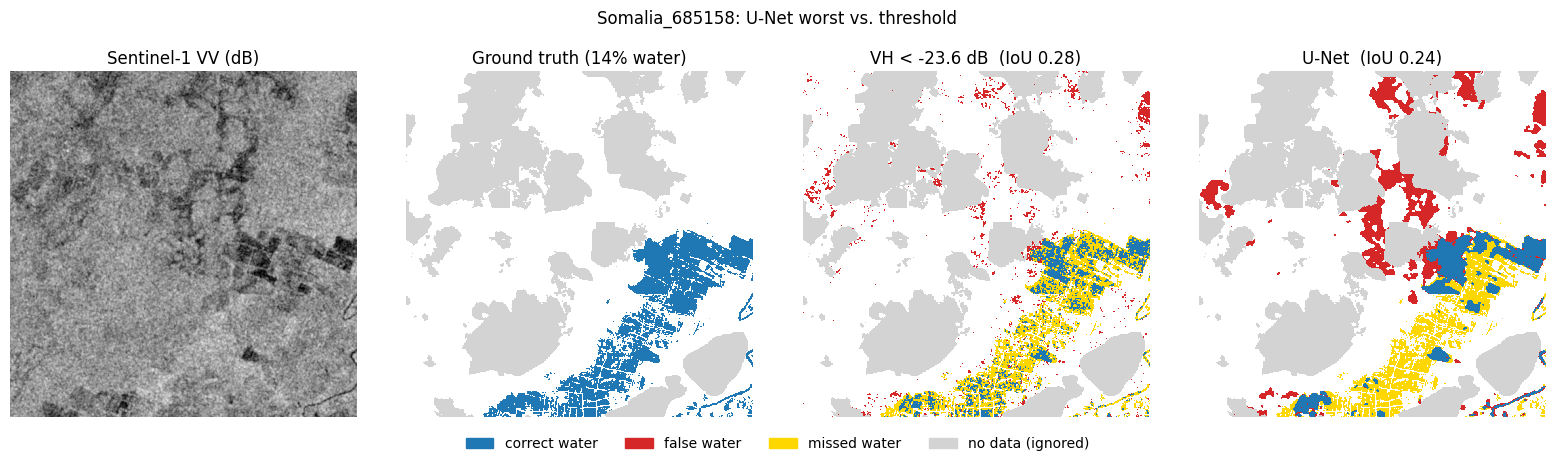

In [7]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

os.makedirs('/content/export/figures', exist_ok=True)
GT_CMAP = ListedColormap(['lightgrey', 'white', 'tab:blue'])                        # -1, 0, 1
ERR_CMAP = ListedColormap(['lightgrey', 'white', 'tab:blue', 'tab:red', 'gold'])    # ignored, TN, TP, FP, FN

def error_map(pred, lab):
    """0 = ignored, 1 = correct land, 2 = correct water, 3 = false water, 4 = missed water."""
    m = np.zeros(lab.shape, dtype=int)
    v, t = lab != -1, lab == 1
    m[v & ~pred & ~t] = 1
    m[v & pred & t] = 2
    m[v & pred & ~t] = 3
    m[v & ~pred & t] = 4
    return m

def plot_example(row, path):
    i = test_ds.chip_ids.index(row['chip'])
    s1, _ = load_chip(DATA_DIR, row['chip'])
    lab = test_ds.labels[i]
    fig, ax = plt.subplots(1, 4, figsize=(16, 4.6))
    ax[0].imshow(s1[0], cmap='gray', vmin=-25, vmax=0)
    ax[0].set_title('Sentinel-1 VV (dB)')
    ax[1].imshow(lab, cmap=GT_CMAP, vmin=-1, vmax=1, interpolation='nearest')
    ax[1].set_title(f"Ground truth ({row['water_%']:.0f}% water)")
    ax[2].imshow(error_map(s1[1] < T_VH, lab), cmap=ERR_CMAP, vmin=0, vmax=4, interpolation='nearest')
    ax[2].set_title(f"VH < {T_VH} dB  (IoU {row['iou_vh']:.2f})")
    ax[3].imshow(error_map(preds['test'][i], lab), cmap=ERR_CMAP, vmin=0, vmax=4, interpolation='nearest')
    ax[3].set_title(f"U-Net  (IoU {row['iou_unet']:.2f})")
    for a in ax:
        a.axis('off')
    fig.legend(handles=[Patch(color='tab:blue', label='correct water'),
                        Patch(color='tab:red', label='false water'),
                        Patch(color='gold', label='missed water'),
                        Patch(color='lightgrey', label='no data (ignored)')],
               loc='lower center', ncol=4, frameon=False)
    fig.suptitle(f"{row['chip']}: {row['why']}")
    plt.tight_layout(rect=(0, 0.06, 1, 0.95))
    fig.savefig(path, dpi=120, bbox_inches='tight')
    plt.show()

for k, (_, row) in enumerate(picks.iterrows(), start=1):
    plot_example(row, f"/content/export/figures/example_{k}_{row['chip']}.png")

In [8]:
os.makedirs('/content/export/results', exist_ok=True)
ev.round(3).to_csv('/content/export/results/test_iou_per_event.csv')
chips.round(4).to_csv('/content/export/results/test_iou_per_chip.csv', index=False)
picks.round(4).to_csv('/content/export/results/example_selection.csv', index=False)

!cd /content/export && zip -qr /content/step5_outputs.zip figures results
from google.colab import files
files.download('/content/step5_outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>